# Oil Spill Simulation w/ OpenDrift and Norkyst

[OpenDrift](https://opendrift.github.io/#) is a Lagrangian particle advection code that evolves particles along precomputed velocity fields. The fields are provided by an metocean model. [OpenOil](https://opendrift.github.io/autoapi/opendrift/models/openoil/openoil/index.html) is a component (module) of OpenDrift that models to behaviour of different types of oil.

It is important to note that oil particles do not affect the fluid dynamics -- OpenDrift / OpenOil are purely post-processing. For more realistic oil spill modelling, oil needs to be explicitly modelled as a fluid in the simulation. This can be achived with the suite of [SINMOD](https://www.sintef.no/programvare/sinmod/), [OSCAR](https://www.sintef.no/programvare/oscar-oil-spill-contingency-and-response/), and [DREAM](https://www.sintef.no/programvare/dream-numerisk-miljomodell/).

This noteook demonstrates how to use OpenDrift / OpenOil to simulate (or risk assess) oil spills from oig & gas installations along the Norwegian continental shelf. It covers the following steps:

1. Load (publicly available) location of oil & gas installations in Norway
2. Seed a number of oil particles at the locations
3. Evolve the particles over a number of hours
4. Generate some example figures

## Imports, etc

In [1]:
import datetime
import geopandas as gpd
import numpy as np

# from opendrift.models.oceandrift import OceanDrift
from opendrift.models.openoil import OpenOil
from opendrift.models.sedimentdrift import OceanDrift
from opendrift.readers import reader_netCDF_CF_generic

In [2]:
import opendrift
opendrift.__version__

'1.14.11'

## Download Data

First, we source [Offshore Oil & Gas Installations](https://ows.emodnet-humanactivities.eu/geonetwork/srv/api/records/ddbe3597-4e3f-4e74-8d31-947c4efef2e9) from the [EMODNet Human Activities](https://emodnet.ec.europa.eu/en/human-activities) dataset.

In [3]:
!mkdir -p ../data

In [4]:
# See https://emodnet.ec.europa.eu/en/human-activities
# See https://ows.emodnet-humanactivities.eu/geonetwork/srv/api/records/ddbe3597-4e3f-4e74-8d31-947c4efef2e9
# URL = "https://ows.emodnet-humanactivities.eu/geonetwork/srv/api/records/ddbe3597-4e3f-4e74-8d31-947c4efef2e9/attachments/EMODnet_HA_OG_Offshore_Installations_20240216.zip"
!curl -fLO --output-dir ../data https://ows.emodnet-humanactivities.eu/geonetwork/srv/api/records/ddbe3597-4e3f-4e74-8d31-947c4efef2e9/attachments/EMODnet_HA_OG_Offshore_Installations_20240216.zip

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  285k  100  285k    0     0   715k      0 --:--:-- --:--:-- --:--:--  716k


In [5]:
!unzip -oq ../data/EMODnet_HA_OG_Offshore_Installations_20240216.zip -d ../data

# Read Data

There are a lot of installations in this dataset, set we filter on Norway, Subsea, and Crude Oil primary production.

In [6]:
# Read Offshore Installations
gdf = gpd.read_file('../data/EMODnet_HA_OG_Offshore_Installations_20240216.shp')
myfilter = np.logical_and(gdf.COUNTRY == "Norway", gdf.FUNCTION=="Subsea", gdf.PRIM_PROD=="Crude Oil")
gdf = gdf[myfilter]
gdf['CODE'] = gdf['CODE'].astype(int)
# gdf['WD_M'] = gdf['WD_M'].astype(float)  # WD: water depth in metres
gdf = gdf.head(4)

In [7]:
gdf.T

,491,493,494,495
COUNTRY,Norway,Norway,Norway,Norway
CODE,403298,395215,283341,287373
STATUS,Operational,Operational,Operational,Operational
NAME,GJØA B,6407/7-A-4 H,TROLL RB3,DRAUGEN T
CATEGORY,Subsea steel,Subsea steel,Subsea steel,Subsea steel
FUNCTION,Subsea,Subsea,Subsea,Subsea
OPERATOR,Neptune Energy Norge AS,Equinor Energy AS,Equinor Energy AS,Gassco AS
LOC_BLOCK,NO_35/9,NO_6407/7,NO_31/2,NO_6406/11
PRIM_PROD,Crude Oil,Crude Oil,NaN,NaN
WT_SUB_T,0.0,0.0,200.0,0.0


In [8]:
# gdf.info()

# Setup Model

First, we setup / configure the model run.

Note that the ocean model outputs are loaded remotely over OPeNDAP.

This demo uses the [Norkystv3](https://thredds.met.no/thredds/catalog/fou-hi/norkystv3.html) model.

In [9]:
# Init
# o = OceanDrift(loglevel=50)  # Info output (0: debug, 50: no output)
o = OpenOil(loglevel=20)
# o = OpenOil(loglevel=50)

# Reader
norkyst_agg = "https://thredds.met.no/thredds/dodsC/fou-hi/norkystv3_800m_m00_be"
reader_norkyst = reader_netCDF_CF_generic.Reader(norkyst_agg)

# Configure Model
o.add_reader(
    reader_norkyst,
    # variables=["x_sea_water_velocity", "y_sea_water_velocity", "x_wind", "y_wind"],
)
# o.set_config("environment:fallback:x_sea_water_velocity", 0)
# o.set_config("environment:fallback:y_sea_water_velocity", 0)
# o.set_config("drift:horizontal_diffusivity", 1)
# o.set_config("general:coastline_action", "previous")
o.set_config("drift:vertical_mixing", True)
o.set_config("seed:droplet_size_distribution", "uniform")
o.set_config("seed:droplet_diameter_min_subsea", 0.0001)
o.set_config("seed:droplet_diameter_max_subsea", 0.0005)

10:28:13 INFO    opendrift:569: OpenDriftSimulation initialised (version 1.14.11)
10:28:13 INFO    opendrift.readers:67: Opening file with xr.open_dataset
10:28:16 INFO    opendrift.readers.reader_netCDF_CF_generic:340: Detected dimensions: {'x': 'X', 'y': 'Y', 'z': 'depth', 'time': 'time'}
10:28:16 INFO    opendrift.readers.basereader:175: Variable x_sea_water_velocity will be rotated from eastward_sea_water_velocity
10:28:16 INFO    opendrift.readers.basereader:175: Variable y_sea_water_velocity will be rotated from northward_sea_water_velocity
10:28:16 INFO    opendrift.readers.basereader:175: Variable x_wind will be rotated from eastward_wind
10:28:16 INFO    opendrift.readers.basereader:175: Variable y_wind will be rotated from northward_wind


## Seed Particles

For each site selected above, we now seed 256 particles in a radius of 64m of the center coordinates.

The initial time is set to 20 January 2022, 12:30.

In [10]:
# Seed Particles
lons = gdf.geometry.x.values
lats = gdf.geometry.y.values
depths = gdf.WD_M.values
names = list(gdf.NAME.values)
codes = list(gdf.CODE.values)
# time = datetime.datetime.now()
time = datetime.datetime(2025, 1, 20, 12, 30, 0)

for kk in range(len(lons)):
    # print(lons[kk])
    # print(lats[kk])
    # print(names[kk])
    # print(codes[kk])
    # print('***')
    o.seed_elements(
            lon=lons[kk],
            lat=lats[kk],
            z=-depths[kk],
            radius=64,
            number=256,
            # origin_marker=names[kk],
            origin_marker=codes[kk],
            time=time,
        )

10:28:16 INFO    opendrift.models.openoil.openoil:1665: Using uniform droplet size distribution between 0.0001 and 0.0005 m for elements seeded below sea surface.
10:28:16 INFO    opendrift.models.openoil.openoil:1720: Oil type not specified, using default: GENERIC BUNKER C
10:28:16 INFO    opendrift.models.openoil.adios.dirjs:86: Querying ADIOS database for oil: GENERIC BUNKER C
10:28:16 INFO    opendrift.models.openoil.openoil:1731: Using density 988.1 and viscosity 0.021692333877975485 of oiltype GENERIC BUNKER C
10:28:16 INFO    opendrift.models.basemodel.environment:203: Adding a global landmask from GSHHG
10:28:20 INFO    opendrift.models.basemodel.environment:227: Fallback values will be used for the following variables which have no readers: 
10:28:20 INFO    opendrift.models.basemodel.environment:230: 	sea_surface_wave_significant_height: 0.000000
10:28:20 INFO    opendrift.models.basemodel.environment:230: 	sea_surface_wave_stokes_drift_x_velocity: 0.000000
10:28:20 INFO    o

## Run Model

This runs the OpenDrift / OpenOil model for 8 hours with a 600 seconds (10 minute) timestep.

In [11]:
o.run(
    duration=datetime.timedelta(hours=8),
    # duration=datetime.timedelta(days=4),
    time_step=600,
    time_step_output=600
)

10:28:20 INFO    opendrift:1903: Skipping environment variable upward_sea_water_velocity because of condition ['drift:vertical_advection', 'is', False]
10:28:20 INFO    opendrift:1914: Storing previous values of element property lon because of condition (('general:coastline_action', 'in', ['stranding', 'previous']), 'or', ('general:seafloor_action', 'in', ['previous']))
10:28:20 INFO    opendrift:1914: Storing previous values of element property lat because of condition (('general:coastline_action', 'in', ['stranding', 'previous']), 'or', ('general:seafloor_action', 'in', ['previous']))
10:28:20 INFO    opendrift:955: Using existing reader for land_binary_mask to move elements to ocean
10:28:20 INFO    opendrift:986: All points are in ocean
10:28:20 INFO    opendrift.models.openoil.openoil:697: Oil-water surface tension is 0.035935 Nm
10:28:20 INFO    opendrift.models.openoil.openoil:710: Max water fraction not available for GENERIC BUNKER C, using default
10:28:20 INFO    opendrift:22

<xarray.Dataset> Size: 9MB
Dimensions:                                                                              (
                                                                                          trajectory: 1024,
                                                                                          time: 49)
Coordinates:
  * trajectory                                                                           (trajectory) int64 8kB ...
  * time                                                                                 (time) datetime64[us] 392B ...
Data variables: (12/44)
    status                                                                               (trajectory, time) float32 201kB ...
    moving                                                                               (trajectory, time) float32 201kB ...
    age_seconds                                                                          (trajectory, time) float32 201kB ...
    origin_marker                                                                        (trajectory, time) float32 201kB ...
    lon                                                                                  (trajectory, time) float32 201kB ...
    lat                                                                                  (trajectory, time) float32 201kB ...
    ...                                                                                   ...
    sea_water_salinity                                                                   (trajectory, time) float32 201kB ...
    sea_floor_depth_below_sea_level                                                      (trajectory, time) float32 201kB ...
    horizontal_diffusivity                                                               (trajectory, time) float32 201kB ...
    ocean_vertical_diffusivity                                                           (trajectory, time) float32 201kB ...
    land_binary_mask                                                                     (trajectory, time) float32 201kB ...
    ocean_mixed_layer_thickness                                                          (trajectory, time) float32 201kB ...
Attributes: (12/167)
    Conventions:                                                             ...
    standard_name_vocabulary:                                                ...
    featureType:                                                             ...
    title:                                                                   ...
    summary:                                                                 ...
    keywords:                                                                ...
    ...                                                                                                               ...
    geospatial_lon_units:                                                    ...
    geospatial_lon_resolution:                                               ...
    runtime:                                                                 ...
    geospatial_vertical_min:                                                 ...
    geospatial_vertical_max:                                                 ...
    geospatial_vertical_positive:                                            ...

## Generate Figures

This generates figures about how the oil particles move about on a map (above) as well as the dispersal and submergion (below).

10:28:42 WARNING opendrift:2589: Plotting fast. This will make your plots less accurate.


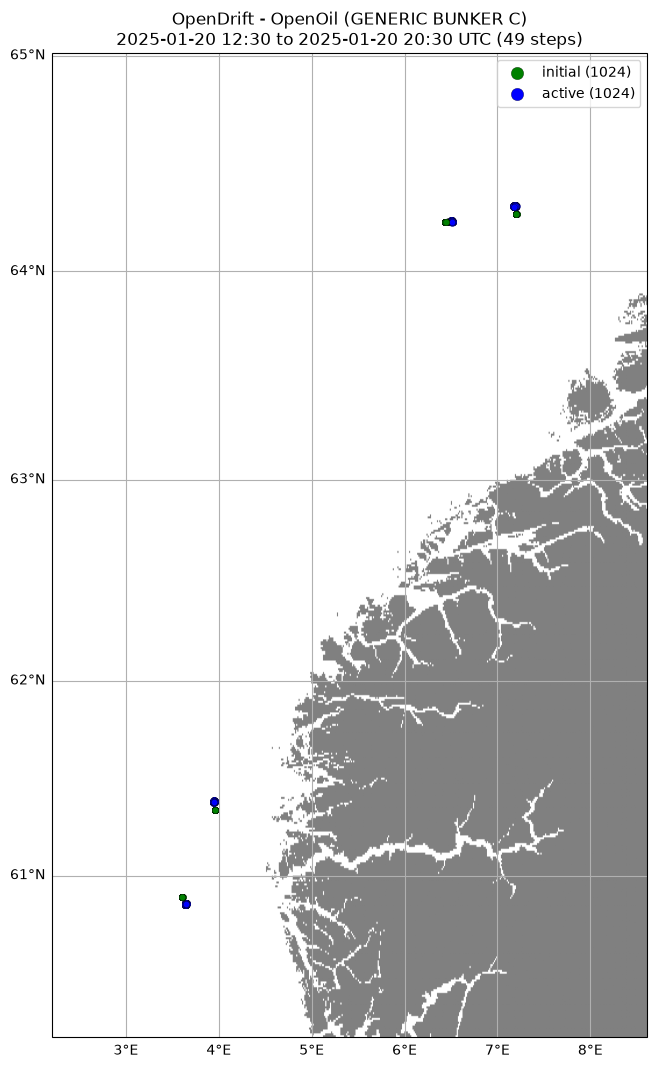

In [12]:
o.plot(buffer=.7, fast=True)
# o.plot(byffer=.7)
pass

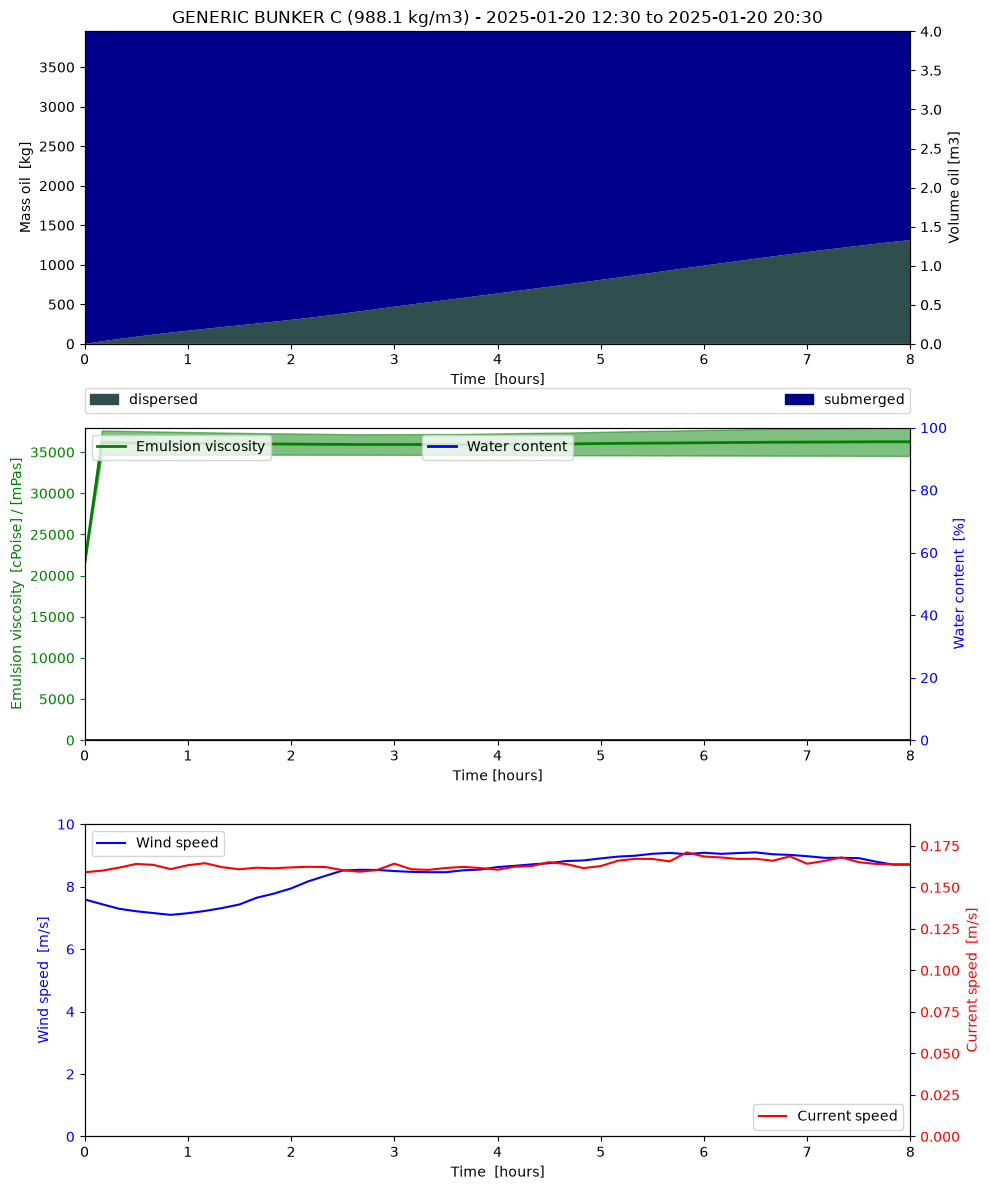

In [13]:
# o.animation_profile(markersize='z', color='z')
o.plot_oil_budget()
pass